
<table style="background-color: transparent;">
    <tr style="background-color: transparent; text-align:center;">
        <td width="100%" align="center"><font size="7" color="#6366F1">Computación Cuántica</font></td>
    </tr>
    <tr style="background-color: transparent; text-align:center;">
        <td width="100%"><font size="4" color="black">Temas Selectos de Ingeniería en Computación III</font></td>
    </tr>
    <tr style="background-color: transparent; text-align:center;">
        <td width="100%"><font size="4" color="black">2027-1</font></td>
    </tr>

  <tr style="background-color: transparent; text-align:center;">
      <td width="100%">
          <font size="6" color="#6366F1">
              Laboratorio 7:<br>
              Aprendizaje Automático Cuántico y Algoritmos Variacionales de Optimización
          </font>
    </td>
    </tr>
</table>



$$
\begin{gathered}
\phantom{\Large X}\\[5pt]
\huge \text{Quantum k-Nearest Neighbors (QkNN) mediante SWAP Test}
\end{gathered}
$$


### *Autor: Sebastián González Juárez*
---


# **Contenido**

1. [**Similitud y fidelidad cuántica**](#seccion-1)
2. [**SWAP Test**](#seccion-2)
3. [**k vecinos más cercanos (kNN) clásico**](#seccion-3)
4. [**Conjunto de datos Iris**](#seccion-4)
5. [**Quantum k-Nearest Neighbors (QkNN)**](#seccion-5)

In [1]:
%pip -q install pennylane

You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.



<a name="seccion-1"></a>

# **1. Similitud y fidelidad cuántica**


La **fidelidad cuántica** permite cuantificar el grado de **similitud entre dos estados cuánticos** puros y normalizados a partir del módulo cuadrado de su producto interno. Su valor está comprendido entre $0$ y $1$: es máximo cuando los estados difieren, a lo sumo, por una fase global, y nulo cuando son ortogonales.

En este laboratorio calcularemos la fidelidad directamente y posteriormente mediante el **SWAP Test**, para utilizarla como criterio de similitud en un clasificador **Quantum k-Nearest Neighbors (QkNN)**.

## 1.1. Definición matemática de la fidelidad

Consideremos dos estados cuánticos puros y normalizados de $n$ qubits:

$$
|\psi\rangle=\sum_{j=0}^{2^n-1}\alpha_j|j\rangle,
\qquad
|\phi\rangle=\sum_{j=0}^{2^n-1}\beta_j|j\rangle.
$$

Cada estado contiene $2^n$ amplitudes complejas. Los coeficientes $\alpha_j$ y $\beta_j$ corresponden a las amplitudes del estado base $|j\rangle$ en $|\psi\rangle$ y $|\phi\rangle$, respectivamente. El índice $j$ enumera las componentes desde $0$ hasta $2^n-1$.

Por ejemplo, para $n=2$:

$$
|\psi\rangle=
\underbrace{\alpha_0|00\rangle}_{j=0}+
\underbrace{\alpha_1|01\rangle}_{j=1}+
\underbrace{\alpha_2|10\rangle}_{j=2}+
\underbrace{\alpha_3|11\rangle}_{j=3}.
$$

El producto interno entre ambos estados es

$$
\langle\psi|\phi\rangle
=\sum_{j=0}^{2^n-1}\alpha_j^*\beta_j,
$$

donde $\alpha_j^*$ representa el conjugado complejo de $\alpha_j$.

La **fidelidad entre estados puros** se define como

$$
\boxed{F(\psi,\phi)=|\langle\psi|\phi\rangle|^2}.
$$



## 1.2. Interpretación y ejemplos de fidelidad

La fidelidad satisface $0\leq F(\psi,\phi)\leq 1$:

- **$F=1$:** los estados son físicamente equivalentes, aunque puedan diferir por una fase global.
- **$F=0$:** los estados son ortogonales.
- **$0<F<1$:** presentan una similitud intermedia.

Consideremos tres ejemplos:

**1. Estados idénticos**

$$
F(|0\rangle,|0\rangle)=|\langle0|0\rangle|^2=1.
$$

**2. Estados ortogonales**

$$
F(|0\rangle,|1\rangle)=|\langle0|1\rangle|^2=0.
$$

**3. Estados con similitud intermedia**

$$
F(|0\rangle,|+\rangle)
=|\langle0|+\rangle|^2
=\frac12.
$$

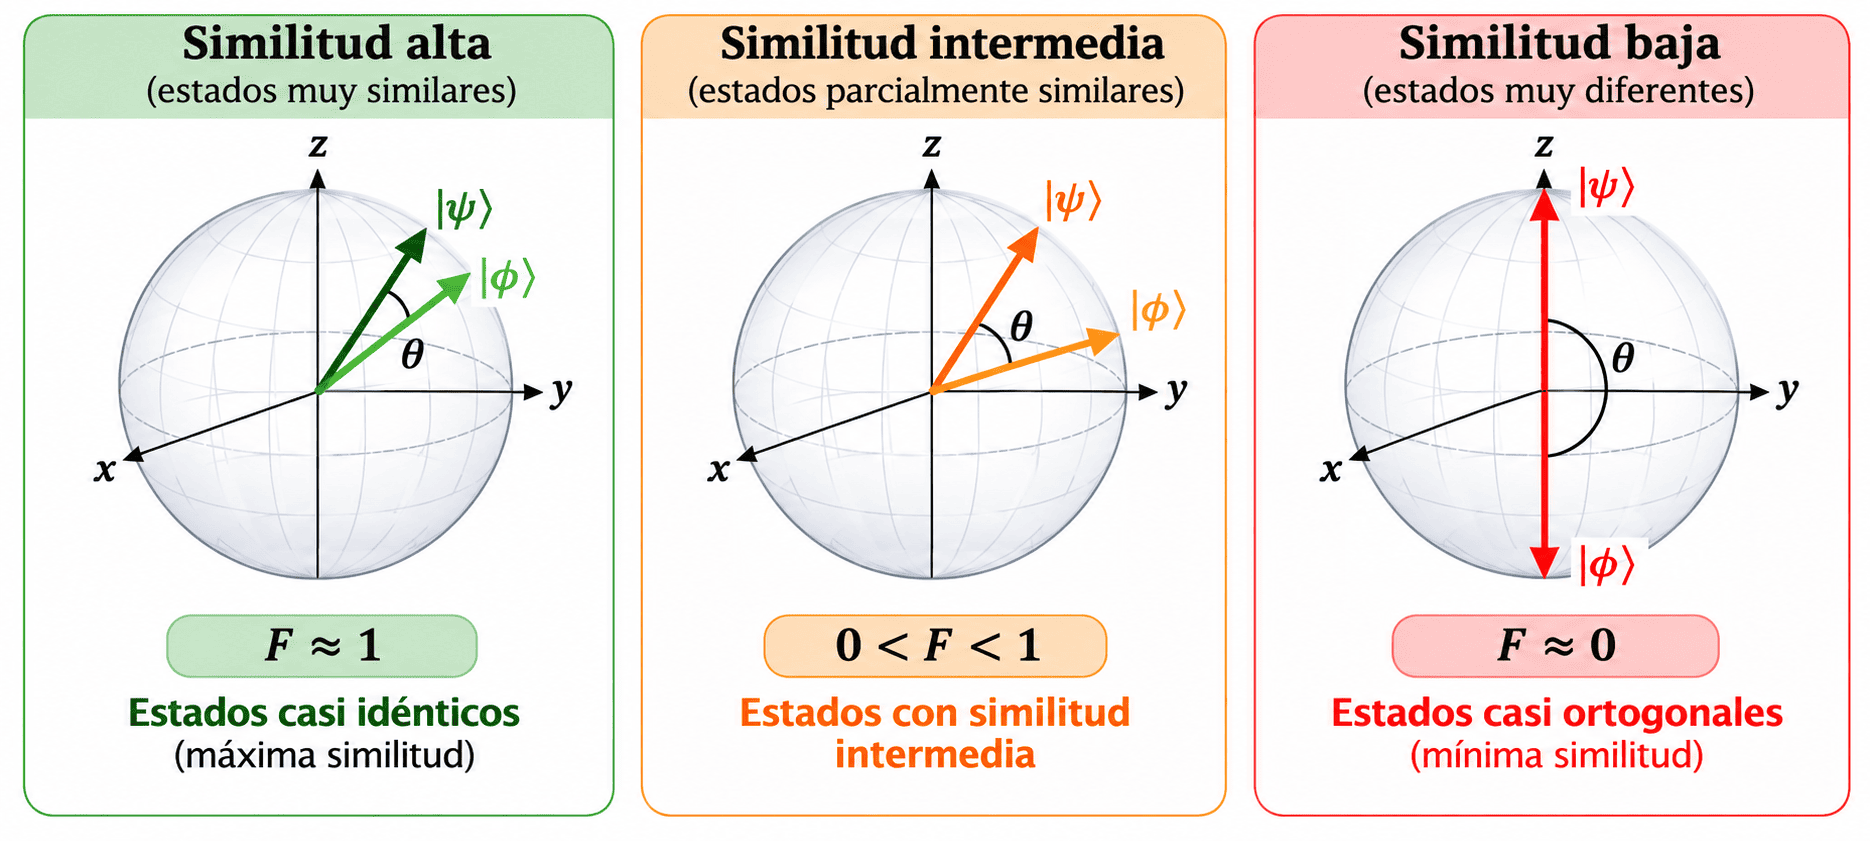


## 1.3. Cálculo directo de fidelidad con PennyLane

Prepararemos los estados $|0\rangle$, $|1\rangle$ y $|+\rangle$ mediante rotaciones $R_Y(\theta)$ sobre un qubit:

$$
R_Y(0)|0\rangle=|0\rangle,
\qquad
R_Y(\pi)|0\rangle=|1\rangle,
\qquad
R_Y\left(\frac{\pi}{2}\right)|0\rangle=|+\rangle.
$$

Utilizaremos el simulador `default.qubit` de PennyLane para obtener los vectores de estado y calcular sus fidelidades.


In [2]:
import pennylane as qml
import numpy as np

dev = qml.device("default.qubit", wires=1)  # Simulador de un qubit

@qml.qnode(dev)
def preparar_estado(theta):
    qml.RY(theta, wires=0)                   # Rotación alrededor del eje Y
    return qml.state()

ket_0 = preparar_estado(0)                   # Estado |0>
ket_1 = preparar_estado(np.pi)               # Estado |1> (hasta fase global)
ket_plus = preparar_estado(np.pi / 2)        # Estado |+>

print("|0> =", ket_0)
print("|1> =", ket_1)
print("|+> =", ket_plus)

/Users/karla/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


|0> = [1.+0.j 0.+0.j]
|1> = [6.123234e-17+0.j 1.000000e+00+0.j]
|+> = [0.70710678+0.j 0.70710678+0.j]


La función `qml.math.fidelity_statevector(psi, phi)` calcula la fidelidad entre dos estados puros a partir de sus vectores:

$$
F(\psi,\phi)=|\langle\psi|\phi\rangle|^2.
$$

Este cálculo utiliza directamente las amplitudes proporcionadas por el simulador, sin realizar mediciones.


In [3]:
def fidelidad(psi, phi):
    return qml.math.fidelity_statevector(psi, phi)  # Fidelidad entre estados puros

In [4]:
ejemplos = [
    ("Estados idénticos", ket_0, ket_0),        # Fidelidad teórica: 1
    ("Estados ortogonales", ket_0, ket_1),      # Fidelidad teórica: 0
    ("Similitud intermedia", ket_0, ket_plus)   # Fidelidad teórica: 0.5
]

for nombre, psi, phi in ejemplos:
    F = fidelidad(psi, phi)                     # Calcular fidelidad
    print(f"{nombre}: F = {F:.4f}")            # Mostrar cuatro decimales

Estados idénticos: F = 1.0000
Estados ortogonales: F = 0.0000
Similitud intermedia: F = 0.5000


Los valores calculados coinciden con los resultados teóricos.

Hasta ahora hemos utilizado los vectores de estado proporcionados por el simulador. En la siguiente sección implementaremos el **SWAP Test** para estimar estas mismas fidelidades a partir de mediciones de un circuito cuántico.



<a name="seccion-2"></a>

# **2. SWAP Test**


El **SWAP Test** es un algoritmo cuántico que permite estimar la fidelidad entre dos estados cuánticos puros mediante la medición de un qubit auxiliar, sin necesidad de conocer explícitamente sus amplitudes.

Analizaremos su circuito, deduciremos la relación entre las probabilidades de medición y la fidelidad, y verificaremos su funcionamiento mediante PennyLane.


## 2.1. Circuito del SWAP Test

El circuito utiliza un qubit auxiliar inicializado en $|0\rangle$ y dos registros cuánticos preparados en los estados $|\psi\rangle$ y $|\phi\rangle$, que deseamos comparar.

El algoritmo consta de cuatro operaciones:

1. **Hadamard ($H$):** crea una superposición en el qubit auxiliar.
2. **SWAP controlada (CSWAP):** intercambia los registros cuando el auxiliar está en $|1\rangle$.
3. **Hadamard ($H$):** permite obtener información sobre la similitud de los estados al medir el auxiliar.
4. **Medición:** se mide el qubit auxiliar en la base computacional.

La operación CSWAP actúa como

$$
\operatorname{CSWAP}|0\rangle_a|\psi\rangle|\phi\rangle
=|0\rangle_a|\psi\rangle|\phi\rangle,
$$

$$
\operatorname{CSWAP}|1\rangle_a|\psi\rangle|\phi\rangle
=|1\rangle_a|\phi\rangle|\psi\rangle.
$$

Para registros de $n$ qubits, el intercambio controlado requiere $n$ compuertas CSWAP, una por cada par de qubits correspondientes.


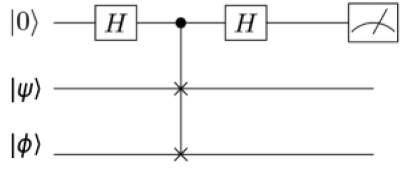


## 2.2. Evolución del estado y relación con la fidelidad

#### ***I.** Estado inicial*

Consideremos dos estados cuánticos puros y normalizados, $|\psi\rangle$ y $|\phi\rangle$, junto con un qubit auxiliar inicializado en $|0\rangle$.

El estado inicial del sistema es

$$
|\Psi_0\rangle=|0\rangle_a|\psi\rangle|\phi\rangle,
$$

donde el subíndice $a$ identifica al qubit auxiliar.

#### ***II.** Primera Hadamard*

La compuerta Hadamard genera una superposición en el qubit auxiliar:

$$
H|0\rangle=\frac{|0\rangle+|1\rangle}{\sqrt{2}}.
$$

El estado completo queda

$$
|\Psi_1\rangle=
\frac{1}{\sqrt{2}}
\left(
|0\rangle_a|\psi\rangle|\phi\rangle+
|1\rangle_a|\psi\rangle|\phi\rangle
\right).
$$


#### ***III.** SWAP controlada (CSWAP)*

Cuando el auxiliar está en $|0\rangle$, los registros permanecen iguales; cuando está en $|1\rangle$, se intercambian.

Por lo tanto,

$$
|\Psi_2\rangle=
\frac{1}{\sqrt{2}}
\left(
|0\rangle_a|\psi\rangle|\phi\rangle+
|1\rangle_a|\phi\rangle|\psi\rangle
\right).
$$

#### ***IV.** Segunda Hadamard*

Aplicamos nuevamente Hadamard al qubit auxiliar:

$$
H|0\rangle=\frac{|0\rangle+|1\rangle}{\sqrt{2}},
\qquad
H|1\rangle=\frac{|0\rangle-|1\rangle}{\sqrt{2}}.
$$

Sustituyendo y agrupando los términos correspondientes a cada resultado del auxiliar:

$$
|\Psi_3\rangle=
\frac{1}{2}
\Big[
|0\rangle_a
\left(
|\psi\rangle|\phi\rangle+
|\phi\rangle|\psi\rangle
\right)
+
|1\rangle_a
\left(
|\psi\rangle|\phi\rangle-
|\phi\rangle|\psi\rangle
\right)
\Big].
$$


#### ***V.** Probabilidad de medir el qubit auxiliar en $|0\rangle$*

A partir del estado obtenido después de la segunda Hadamard, identificamos la componente asociada al resultado $|0\rangle_a$:

$$
\frac{1}{2}\left(|\psi\rangle|\phi\rangle+|\phi\rangle|\psi\rangle\right).
$$

La probabilidad de obtener este resultado corresponde a su norma al cuadrado:

$$
P(0)=\frac14\left\||\psi\rangle|\phi\rangle+|\phi\rangle|\psi\rangle\right\|^2.
$$

#### ***VI.** Desarrollo del producto interno*

Utilizando la propiedad $\||v\rangle\|^2=\langle v|v\rangle$:

$$
P(0)=\frac14\left(\langle\psi|\langle\phi|+\langle\phi|\langle\psi|\right)\left(|\psi\rangle|\phi\rangle+|\phi\rangle|\psi\rangle\right).
$$

Al desarrollar el producto de las dos sumas, obtenemos cuatro términos:

$$
P(0)=\frac14\left[\langle\psi|\psi\rangle\langle\phi|\phi\rangle+\langle\psi|\phi\rangle\langle\phi|\psi\rangle+\langle\phi|\psi\rangle\langle\psi|\phi\rangle+\langle\phi|\phi\rangle\langle\psi|\psi\rangle\right].
$$

Como ambos estados están normalizados,

$$
\langle\psi|\psi\rangle=\langle\phi|\phi\rangle=1,
$$

Sustituyendo:

$$
P(0)=\frac14\left[2+\langle\psi|\phi\rangle\langle\phi|\psi\rangle+\langle\phi|\psi\rangle\langle\psi|\phi\rangle\right].
$$

Además, el producto interno cumple la propiedad de simetría conjugada:

$$
\langle\phi|\psi\rangle=\langle\psi|\phi\rangle^*.
$$

Por lo tanto, los dos términos cruzados son iguales a

$$
\langle\psi|\phi\rangle\langle\phi|\psi\rangle=|\langle\psi|\phi\rangle|^2.
$$

Sustituyendo:

$$
P(0)=\frac14\left(2+2|\langle\psi|\phi\rangle|^2\right).
$$

Simplificando:

$$
P(0)=\frac12\left(1+|\langle\psi|\phi\rangle|^2\right).
$$

#### ***VII.** Relación con la fidelidad*

Recordando la definición de fidelidad de la sección 1:

$$
F(\psi,\phi)=|\langle\psi|\phi\rangle|^2,
$$

obtenemos

$$
\boxed{P(0)=\frac{1+F(\psi,\phi)}{2}}.
$$

Finalmente, despejamos la fidelidad:

$$
2P(0)=1+F(\psi,\phi).
$$

$$
\boxed{F(\psi,\phi)=2P(0)-1}.
$$

Esta expresión permite determinar la fidelidad entre los estados $|\psi\rangle$ y $|\phi\rangle$ a partir de la probabilidad de medir el qubit auxiliar en $|0\rangle$.


## 2.3. Implementación del SWAP Test con PennyLane

Implementaremos el **SWAP Test** utilizando tres qubits:

- **Qubit 0:** auxiliar, inicializado en $|0\rangle$.
- **Qubit 1:** estado $|\psi\rangle$.
- **Qubit 2:** estado $|\phi\rangle$.

Utilizaremos rotaciones $R_Y(\theta)$ para preparar los estados, como en la sección 1, e incorporaremos las compuertas Hadamard y CSWAP para implementar el algoritmo.

Primero obtendremos las probabilidades teóricas de medición del qubit auxiliar mediante `qml.probs`. En la sección 2.4 estimaremos esas probabilidades utilizando un número finito de mediciones (*shots*).


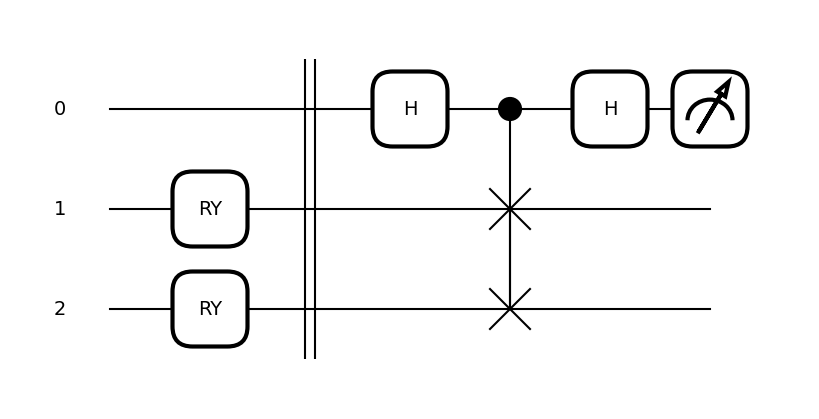

In [5]:
import matplotlib.pyplot as plt                              # Visualización de circuitos

dev_swap = qml.device("default.qubit", wires=3)              # Simulador de tres qubits

@qml.qnode(dev_swap)
def swap_test_exacto(theta_psi, theta_phi):
    qml.RY(theta_psi, wires=1)                               # Preparar |psi>
    qml.RY(theta_phi, wires=2)                               # Preparar |phi>
    qml.Barrier(wires=[0, 1, 2])                              # Separar preparación del SWAP Test

    qml.Hadamard(wires=0)                                    # Primera Hadamard
    qml.CSWAP(wires=[0, 1, 2])                               # Intercambio controlado
    qml.Hadamard(wires=0)                                    # Segunda Hadamard

    return qml.probs(wires=[0])                              # Probabilidades P(0) y P(1)

fig, ax = qml.draw_mpl(swap_test_exacto)(0.0, np.pi / 2)     # Visualizar el circuito |0> vs |+>
plt.show()                                                   # Mostrar circuito


La función `qml.probs(wires=[0])` devuelve $[P(0),P(1)]$. Recuperamos la fidelidad mediante la relación deducida en 2.2:

$$
F(\psi,\phi)=2P(0)-1.
$$

In [6]:
casos = [
    ("|0> vs |0>", 0.0, 0.0),                                # Estados idénticos
    ("|0> vs |1>", 0.0, np.pi),                              # Estados ortogonales
    ("|0> vs |+>", 0.0, np.pi / 2)                           # Similitud intermedia
]

for nombre, theta_psi, theta_phi in casos:
    p0 = swap_test_exacto(theta_psi, theta_phi)[0]           # Probabilidad de medir el auxiliar en 0
    F = 2 * p0 - 1                                           # Fidelidad mediante SWAP Test
    print(f"{nombre:<15} P(0) = {p0:.4f}    F = {F:.4f}")    # Mostrar ambos resultados

|0> vs |0>      P(0) = 1.0000    F = 1.0000
|0> vs |1>      P(0) = 0.5000    F = -0.0000
|0> vs |+>      P(0) = 0.7500    F = 0.5000



### 2.4. Verificación del SWAP Test mediante mediciones

En la sección 2.3 obtuvimos las probabilidades exactas del qubit auxiliar mediante `qml.probs`. Ahora estimaremos estas probabilidades simulando un número finito de mediciones (*shots*).

Si ejecutamos el circuito $N$ veces y obtenemos el resultado $0$ en $N_0$ ocasiones, la probabilidad estimada es

$$
\widehat{P}(0)=\frac{N_0}{N}.
$$

Por tanto, la fidelidad estimada mediante el SWAP Test es

$$
\boxed{\widehat{F}(\psi,\phi)=2\frac{N_0}{N}-1}.
$$

Compararemos los tres casos de la sección anterior utilizando $1000$ shots por experimento.


In [7]:
N_SHOTS = 1000                                               # Número de mediciones por experimento
dev_shots = qml.device("default.qubit", wires=3,
                       shots=N_SHOTS, seed=87)                # Simulador con muestreo reproducible

@qml.qnode(dev_shots)
def swap_test_shots(theta_psi, theta_phi):
    qml.RY(theta_psi, wires=1)                               # Preparar |psi>
    qml.RY(theta_phi, wires=2)                               # Preparar |phi>
    qml.Barrier(wires=[0, 1, 2])                              # Separar preparación y SWAP Test

    qml.Hadamard(wires=0)                                    # Primera Hadamard
    qml.CSWAP(wires=[0, 1, 2])                               # Intercambio controlado
    qml.Hadamard(wires=0)                                    # Segunda Hadamard

    return qml.sample(wires=[0])                             # Obtener N_SHOTS resultados del auxiliar

In [8]:
print(f"{'Estados':<15} {'F exacta':>10} {'F shots':>10} {'Error abs.':>12}")

for nombre, theta_psi, theta_phi in casos:                   # Reutilizar los tres casos de 2.3
    p0 = swap_test_exacto(theta_psi, theta_phi)[0]           # Probabilidad exacta P(0)
    F_exacta = 2 * p0 - 1                                    # Fidelidad exacta mediante SWAP Test

    mediciones = swap_test_shots(theta_psi, theta_phi)       # Ejecutar 1000 mediciones
    n0 = np.sum(mediciones == 0)                              # Contar resultados iguales a 0
    F_shots = 2 * n0 / N_SHOTS - 1                            # Estimar la fidelidad

    error = abs(F_exacta - F_shots)                          # Diferencia absoluta entre ambos cálculos

    print(f"{nombre:<15} {F_exacta:>10.4f} {F_shots:>10.4f} {error:>12.4f}")

Estados           F exacta    F shots   Error abs.
|0> vs |0>          1.0000     1.0000       0.0000
|0> vs |1>         -0.0000    -0.0480       0.0480
|0> vs |+>          0.5000     0.4640       0.0360


Los resultados permiten comprobar que el SWAP Test estima la fidelidad mediante mediciones del qubit auxiliar. Las diferencias respecto al valor exacto se deben a las fluctuaciones estadísticas asociadas al número finito de shots.

Con ello hemos verificado el funcionamiento del algoritmo, que posteriormente utilizaremos para comparar datos codificados en estados cuánticos dentro del clasificador **Quantum k-Nearest Neighbors (QkNN)**.


<a name="seccion-3"></a>

# **3. k vecinos más cercanos (kNN) clásico**


El **aprendizaje automático (Machine Learning, ML)** es una rama de la inteligencia artificial que desarrolla métodos capaces de identificar patrones a partir de datos para realizar predicciones o tomar decisiones, sin establecer explícitamente todas las reglas para cada tarea.

De manera general, distinguimos tres paradigmas principales:

1. **Aprendizaje supervisado:** utiliza datos etiquetados para aprender relaciones entre las características de entrada y sus resultados. Incluye problemas de clasificación y regresión.
2. **Aprendizaje no supervisado:** identifica estructuras o patrones en datos sin etiquetas, como agrupamientos (*clustering*).
3. **Aprendizaje por refuerzo:** estudia cómo un agente aprende a seleccionar acciones mediante su interacción con un entorno y las recompensas recibidas.

En este laboratorio trabajaremos con **clasificación supervisada**, donde el objetivo es asignar una clase a una nueva muestra utilizando información de ejemplos previamente etiquetados.


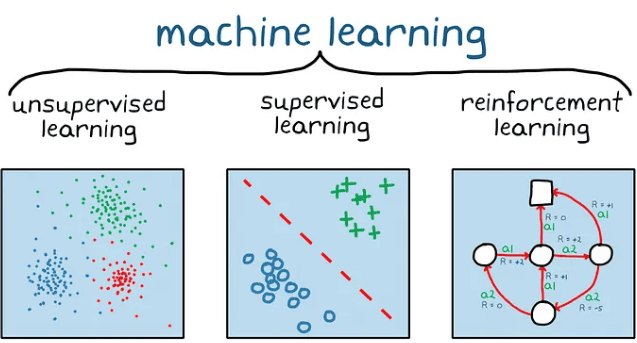


## 3.1. Fundamento del algoritmo kNN

El algoritmo **k vecinos más cercanos (k-Nearest Neighbors, kNN)** es un método de aprendizaje supervisado que clasifica una nueva muestra a partir de las etiquetas de sus $k$ vecinos más cercanos en el conjunto de entrenamiento.

Consideremos un conjunto de entrenamiento etiquetado:

$$
\mathcal{D}=\{(\mathbf{x}_i,y_i)\}_{i=1}^{N},
$$

donde:

- $\mathbf{x}_i\in\mathbb{R}^m$ representa una muestra con $m$ características.
- $y_i$ es la etiqueta de clase correspondiente a $\mathbf{x}_i$.
- $N$ es el número de muestras de entrenamiento.

Dada una nueva muestra $\mathbf{x}$, el algoritmo determina su clase mediante tres pasos:

1. Calcular su distancia respecto a las muestras de entrenamiento.
2. Seleccionar las $k$ muestras con menor distancia.
3. Asignar la clase más frecuente entre los vecinos seleccionados.

El parámetro $k$ determina cuántos vecinos intervienen en la clasificación. A diferencia de otros métodos supervisados, **kNN no ajusta un modelo paramétrico durante el entrenamiento**: conserva las muestras etiquetadas para utilizarlas durante la predicción.



## 3.2. Distancia y selección de vecinos

Para determinar qué muestras son las más cercanas, kNN necesita una **métrica de distancia**. Una de las más utilizadas es la **distancia euclidiana**:

$$
\boxed{d(\mathbf{x},\mathbf{x}_i)=\sqrt{\sum_{j=1}^{m}(x_j-x_{ij})^2}}.
$$

Aquí, $x_j$ y $x_{ij}$ representan la característica $j$ de la muestra por clasificar $\mathbf{x}$ y de la muestra de entrenamiento $\mathbf{x}_i$, respectivamente.

Una vez calculadas las distancias, se ordenan de menor a mayor y se seleccionan las $k$ **muestras más cercanas**.


**Por ejemplo**, con $k=5$, la clasificación utiliza exclusivamente los cinco vecinos con menor distancia respecto a la nueva muestra.


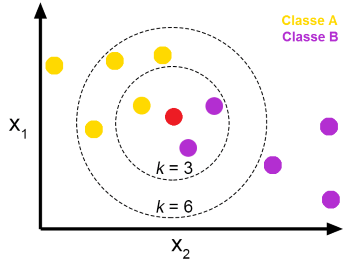

**El valor de $k$ influye en la clasificación:**

- Un valor pequeño hace que la predicción dependa de un número reducido de muestras.
- Un valor grande incorpora más vecinos, pero puede incluir muestras alejadas que pertenecen a otras clases.

Además, cuando las características tienen escalas diferentes, es importante normalizarlas para evitar que las variables de mayor magnitud dominen la distancia.


## 3.3. Regla de clasificación

Una vez seleccionados los $k$ vecinos más cercanos, el algoritmo **kNN asigna a la nueva muestra la clase más frecuente entre sus vecinos**, mediante una votación mayoritaria.

**Ejemplo: clasificación con $k=5$**

Supongamos que los cinco vecinos seleccionados pertenecen a las siguientes clases:

$$
[A,\;B,\;A,\;A,\;B].
$$

Contamos cuántos vecinos pertenecen a cada clase:

$$
V(A)=3,\qquad V(B)=2.
$$

Aquí, $V(c)$ representa el número de votos obtenidos por la clase $c$.

La clase predicha es aquella que recibe más votos:

$$
\boxed{\hat{y}=\underset{c\in\mathcal{C}}{\arg\max}\;V(c)}.
$$

Donde:

- $\hat{y}$ es la clase predicha.
- $\mathcal{C}$ es el conjunto de clases posibles.
- $\arg\max$ identifica la clase con el mayor número de votos.

En nuestro ejemplo, como $V(A)>V(B)$, obtenemos

$$
\boxed{\hat{y}=A}.
$$

En caso de empate, debe establecerse un criterio de desempate.

En el algoritmo QkNN mantendremos esta misma regla de clasificación, pero seleccionaremos los vecinos utilizando la **fidelidad cuántica** como medida de similitud.


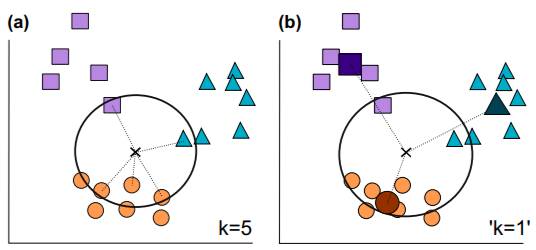


<a name="seccion-4"></a>

# **4. Conjunto de datos Iris**


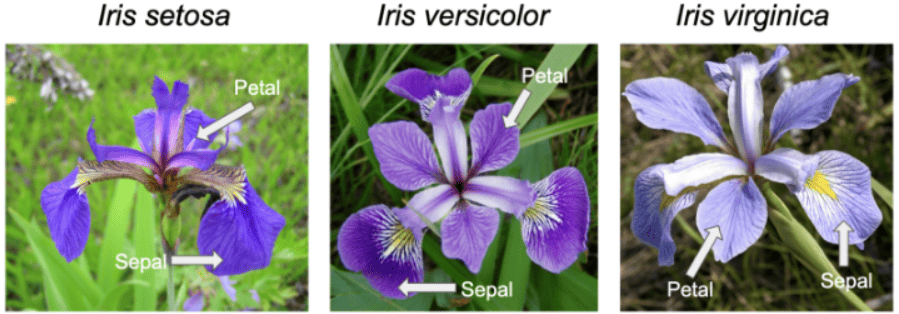

El conjunto de datos **Iris** contiene 150 muestras de flores, distribuidas equitativamente entre tres especies:

- **Iris setosa:** 50 muestras.
- **Iris versicolor:** 50 muestras.
- **Iris virginica:** 50 muestras.

Cada muestra está representada por cuatro características medidas en centímetros: longitud y ancho del sépalo, y longitud y ancho del pétalo.

Matemáticamente, cada flor se representa mediante un vector

$$
\mathbf{x}_i=(x_{i1},x_{i2},x_{i3},x_{i4})\in\mathbb{R}^4,
$$

asociado a una etiqueta $y_i\in\{0,1,2\}$ que identifica su especie.

Trabajaremos con una matriz de características $X\in\mathbb{R}^{150\times4}$ y un vector de etiquetas $y\in\{0,1,2\}^{150}$. Utilizaremos estos datos para implementar el clasificador **kNN clásico** y, posteriormente, su versión cuántica.


In [9]:
from sklearn.datasets import load_iris                    # Conjunto de datos Iris
import pandas as pd

iris = load_iris()                                        # Cargar el conjunto Iris
X = iris.data                                             # Características de las 150 flores
y = iris.target                                           # Etiquetas de las tres especies

df_iris = pd.DataFrame(X, columns=iris.feature_names)     # Construir tabla de características
df_iris["Especie"] = iris.target_names[y]                 # Incorporar los nombres de las especies

print("Dimensiones de X:", X.shape)                       # Número de muestras y características
print("Dimensiones de y:", y.shape)                       # Número de etiquetas
print("\nMuestras por especie:")
print(df_iris["Especie"].value_counts())                   # Distribución de las tres clases

display(df_iris.head())                                   # Mostrar las primeras cinco muestras

Dimensiones de X: (150, 4)
Dimensiones de y: (150,)

Muestras por especie:
Especie
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Especie
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Visualizaremos las relaciones entre las cuatro características de Iris mediante una **matriz de gráficos por pares (*pairplot*)**.

Los gráficos fuera de la diagonal muestran la relación entre dos características, mientras que la diagonal presenta la distribución de cada una. Los colores identifican las tres especies.

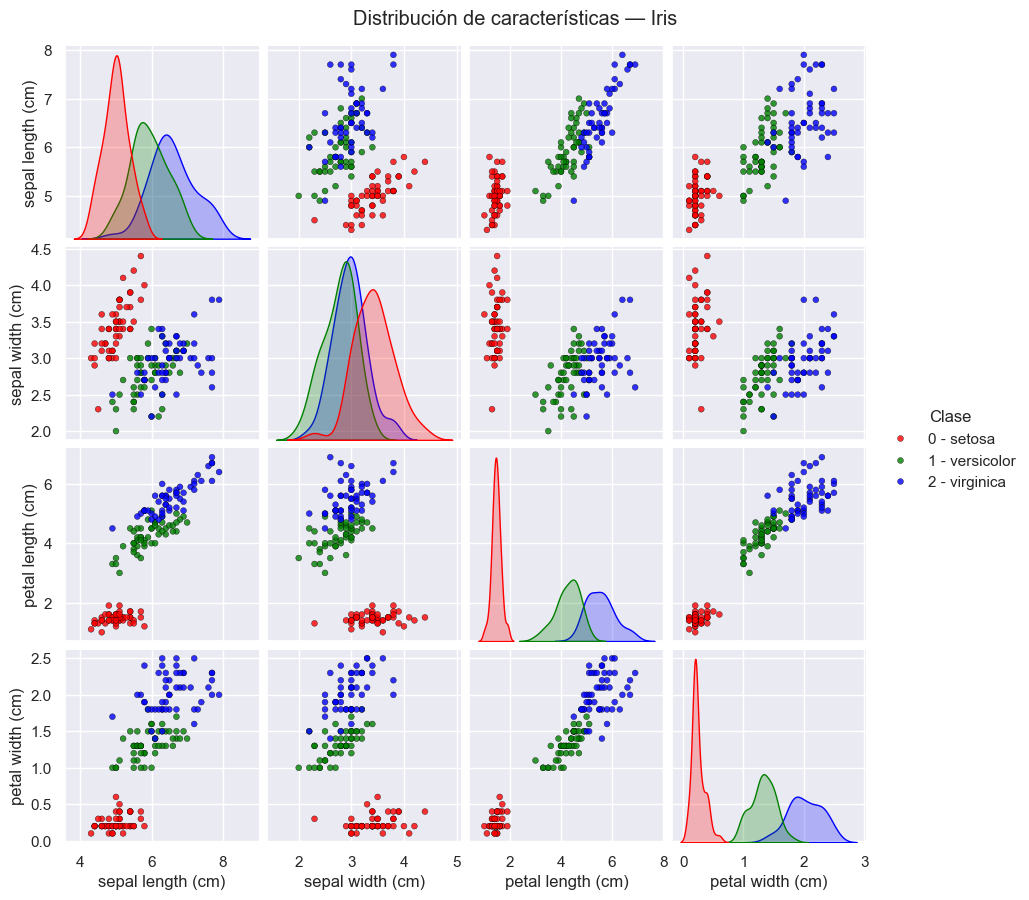

In [10]:
import seaborn as sns

sns.set_theme(style="darkgrid")                                # Estilo de las gráficas

df_iris["Clase"] = [f"{i} - {iris.target_names[i]}" for i in y] # Etiquetas numéricas y nombres

palette = {
    "0 - setosa": "red",                                        # Iris setosa
    "1 - versicolor": "green",                                  # Iris versicolor
    "2 - virginica": "blue"                                     # Iris virginica
}

g = sns.pairplot(
    df_iris[iris.feature_names + ["Clase"]],                    # Cuatro características y clase
    hue="Clase",                                               # Colorear por especie
    palette=palette,                                           # Colores de las tres clases
    diag_kind="kde",                                           # Densidades en la diagonal
    plot_kws={"s": 18, "alpha": 0.8, "edgecolor": "black",
              "linewidth": 0.3},                               # Estilo de los puntos
    height=2.2                                                 # Tamaño de cada panel
)

g.fig.suptitle("Distribución de características — Iris", y=1.02) # Título de la matriz
plt.show()                                                      # Mostrar las 16 gráficas

## 4.1. Preparación de los datos

Dividiremos Iris en dos subconjuntos mediante una partición estratificada:

- **Entrenamiento (80 %):** 120 muestras utilizadas como referencia por el clasificador.
- **Prueba (20 %):** 30 muestras reservadas para evaluar las predicciones.

Aplicaremos una normalización **Min-Max** para llevar cada característica de entrenamiento al intervalo $[0,1]$:

$$
\boxed{x'_{ij}=\frac{x_{ij}-x_j^{\min}}{x_j^{\max}-x_j^{\min}}}.
$$

Los valores $x_j^{\min}$ y $x_j^{\max}$ se calculan exclusivamente con el conjunto de entrenamiento. Después aplicaremos la misma transformación a prueba, evitando **fuga de información (*data leakage*)**.

La separación y normalización serán comunes para kNN y QkNN, garantizando que ambos utilicen las mismas muestras.


In [11]:
from sklearn.model_selection import train_test_split       # División de los datos
from sklearn.preprocessing import MinMaxScaler             # Normalización Min-Max

SEED = 87                                                  # Semilla de reproducibilidad

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y      # División estratificada 80/20
)

scaler = MinMaxScaler()                                     # Escalamiento al intervalo [0, 1]
X_train_scaled = scaler.fit_transform(X_train)              # Ajustar únicamente con entrenamiento
X_test_scaled = scaler.transform(X_test)                    # Transformar prueba sin reajustar

print("Entrenamiento:", X_train_scaled.shape)               # Dimensiones: (120, 4)
print("Prueba:", X_test_scaled.shape)                       # Dimensiones: (30, 4)
print("Clases entrenamiento:", np.bincount(y_train))        # Cantidad de muestras por especie
print("Clases prueba:", np.bincount(y_test))                 # Cantidad de muestras por especie

print("Rango entrenamiento:",
      X_train_scaled.min(), X_train_scaled.max())            # Verificar el escalamiento
print("Rango prueba:",
      X_test_scaled.min(), X_test_scaled.max())               # Verificar extremos de prueba

Entrenamiento: (120, 4)
Prueba: (30, 4)
Clases entrenamiento: [40 40 40]
Clases prueba: [10 10 10]
Rango entrenamiento: 0.0 1.0
Rango prueba: -0.028571428571428692 1.0909090909090908


## 4.2. Clasificación mediante kNN clásico

Implementaremos el clasificador **kNN** utilizando `KNeighborsClassifier` de `scikit-learn`, con distancia euclidiana y $k=5$.

El algoritmo conservará las muestras de entrenamiento como referencia. Para cada muestra de prueba, seleccionará los cinco vecinos más cercanos y asignará la clase mayoritaria, siguiendo la regla estudiada en la sección 3.

Utilizaremos las características normalizadas y evaluaremos las predicciones mediante la **exactitud (accuracy)** y una matriz de confusión.


In [12]:
from sklearn.neighbors import KNeighborsClassifier         # Clasificador kNN
from sklearn.metrics import accuracy_score, confusion_matrix  # Métricas de evaluación

K = 5                                                      # Número de vecinos más cercanos

knn = KNeighborsClassifier(
    n_neighbors=K, metric="euclidean"                       # Cinco vecinos y distancia euclidiana
)

knn.fit(X_train_scaled, y_train)                            # Utilizar muestras etiquetadas de entrenamiento
y_pred_knn = knn.predict(X_test_scaled)                     # Clasificar las 30 muestras de prueba

acc_knn = accuracy_score(y_test, y_pred_knn)                 # Proporción de predicciones correctas
cm_knn = confusion_matrix(y_test, y_pred_knn)               # Matriz de confusión

print(f"Accuracy kNN: {acc_knn:.4f}")                       # Mostrar exactitud en prueba
print("\nMatriz de confusión:")
print(cm_knn)                                               # Comparar etiquetas reales y predichas

Accuracy kNN: 0.9333

Matriz de confusión:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


El clasificador **kNN clásico** obtuvo una exactitud (*accuracy*) del **93.33 %**, clasificando correctamente 28 de las 30 muestras de prueba:

$$
\mathrm{Accuracy}=\frac{N_{\mathrm{correctas}}}{N_{\mathrm{prueba}}}=\frac{28}{30}=0.9333.
$$

La matriz de confusión muestra que:

- **Setosa:** las 10 muestras fueron clasificadas correctamente.
- **Versicolor:** 9 muestras correctas y 1 confundida con virginica.
- **Virginica:** 9 muestras correctas y 1 confundida con versicolor.

Estos resultados servirán como referencia para evaluar el clasificador **Quantum k-Nearest Neighbors (QkNN)** en la siguiente sección, utilizando los mismos conjuntos de entrenamiento y prueba, pero sustituyendo la distancia euclidiana por la **fidelidad cuántica estimada mediante el SWAP Test**.



<a name="seccion-5"></a>

# **5. Quantum k-Nearest Neighbors (QkNN)**


El **Quantum k-Nearest Neighbors (QkNN)** es una adaptación del algoritmo kNN que utiliza estados cuánticos para representar los datos y evaluar su similitud.

En nuestra implementación, sustituiremos la distancia euclidiana por la **fidelidad cuántica obtenida mediante el SWAP Test**. Para clasificar una muestra, seleccionaremos los $k$ estados de entrenamiento con mayor fidelidad y aplicaremos la misma regla de votación mayoritaria del kNN clásico.

Utilizaremos las mismas 120 muestras de entrenamiento, 30 de prueba y $k=5$, lo que permitirá comparar ambos clasificadores bajo las mismas condiciones de datos.



## 5.1. Codificación cuántica de los datos

Para utilizar el SWAP Test, necesitamos representar las cuatro características de cada muestra de Iris mediante un **estado cuántico de cuatro qubits**.

Una muestra normalizada se expresa como

$$
\mathbf{x}=(x_1,x_2,x_3,x_4).
$$

Utilizaremos **codificación por ángulos (*angle encoding*)**, donde cada característica $x_j$ determina una rotación $R_Y$ sobre un qubit diferente:

$$
\theta_j=\pi x_j.
$$

Elegimos $R_Y$ porque permite incorporar el valor de cada característica en las amplitudes del qubit:

$$
R_Y(\theta)|0\rangle=\cos\left(\frac{\theta}{2}\right)|0\rangle+\sin\left(\frac{\theta}{2}\right)|1\rangle.
$$

Los cuatro qubits comienzan en el estado $|0000\rangle$. Aplicando una rotación a cada qubit, obtenemos

$$
\boxed{|\psi(\mathbf{x})\rangle=\left[R_Y(\pi x_1)\otimes R_Y(\pi x_2)\otimes R_Y(\pi x_3)\otimes R_Y(\pi x_4)\right]|0000\rangle}.
$$

Cada rotación actúa sobre un qubit distinto. Por tanto, el registro contiene **cuatro qubits**, cuyo espacio de estados tiene dimensión $2^4=16$.

Para comparar dos muestras $\mathbf{x}$ y $\mathbf{z}$ mediante el SWAP Test, utilizaremos dos registros de cuatro qubits y uno auxiliar:

$$
\boxed{n_{\mathrm{qubits}}=4+4+1=9}.
$$

Esta codificación genera estados producto, sin entrelazamiento entre los qubits de cada registro.


## 5.2. Implementación del SWAP Test para cuatro qubits

Extenderemos el SWAP Test de la sección 2 para comparar dos muestras de Iris, utilizando **nueve qubits**:

- **Qubit 0:** auxiliar del SWAP Test.
- **Qubits 1–4:** codificación de la muestra $\mathbf{x}$.
- **Qubits 5–8:** codificación de la muestra $\mathbf{z}$.

Prepararemos ambos registros mediante rotaciones $R_Y$, incorporaremos una barrera para distinguir la codificación y aplicaremos cuatro compuertas CSWAP, una por cada par de qubits correspondientes.

La fidelidad se obtendrá mediante la relación deducida anteriormente:

$$
\boxed{F(\mathbf{x},\mathbf{z})=2P(0)-1}.
$$

Utilizaremos las probabilidades exactas del simulador `default.qubit`, sin introducir muestreo estadístico.


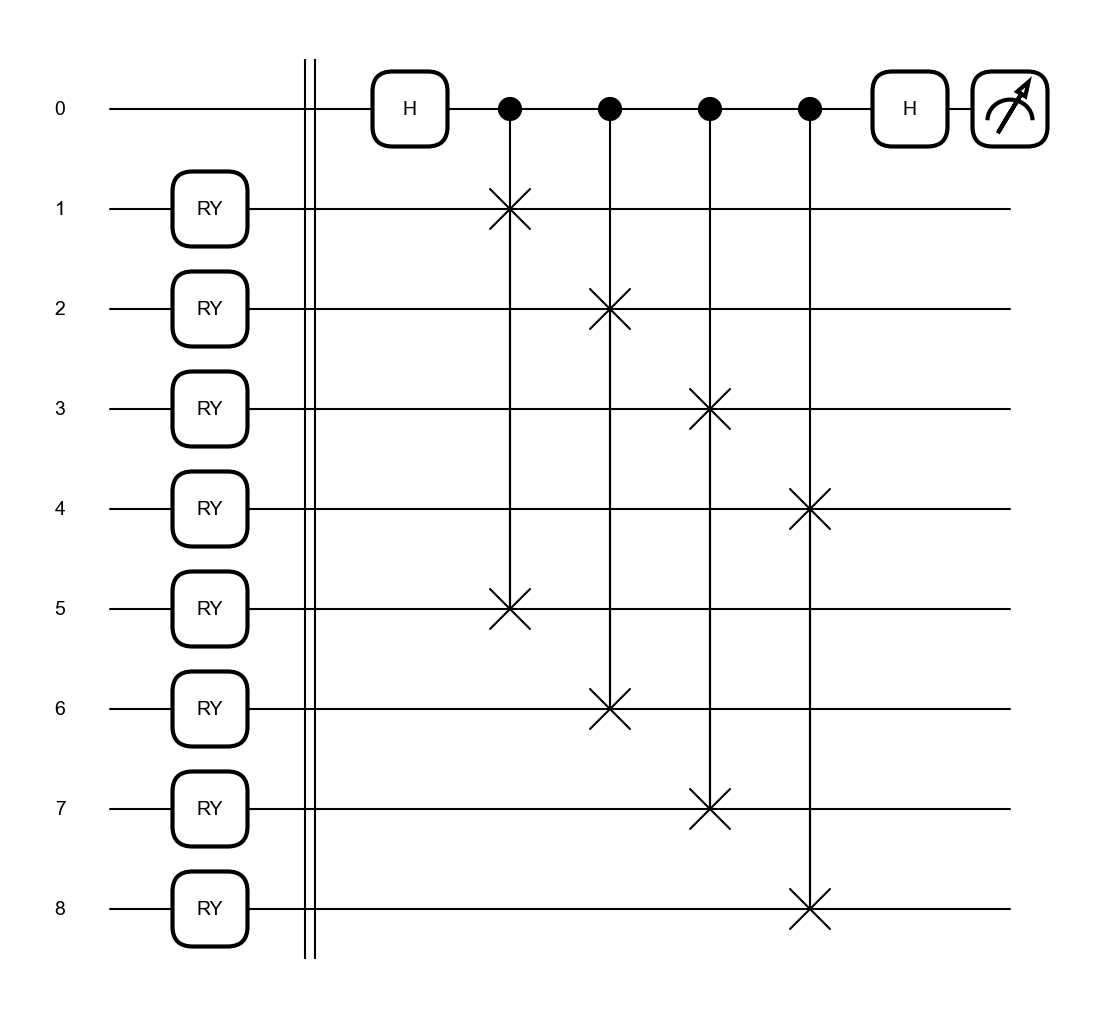

In [13]:
n_features = X_train_scaled.shape[1]                         # Cuatro características por muestra
n_qubits = 2 * n_features + 1                                # Ocho qubits de datos y un auxiliar

dev_qknn = qml.device("default.qubit", wires=n_qubits)        # Simulador de nueve qubits

@qml.qnode(dev_qknn)
def swap_test_iris(x, z):
    for j in range(n_features):
        qml.RY(np.pi * x[j], wires=j + 1)                    # Codificar x en los qubits 1–4
        qml.RY(np.pi * z[j], wires=j + 1 + n_features)       # Codificar z en los qubits 5–8

    qml.Barrier(wires=range(n_qubits))                       # Separar codificación y SWAP Test

    qml.Hadamard(wires=0)                                   # Primera Hadamard del auxiliar

    for j in range(n_features):
        qml.CSWAP(wires=[0, j + 1, j + 1 + n_features])      # Intercambio controlado entre registros

    qml.Hadamard(wires=0)                                   # Segunda Hadamard del auxiliar

    return qml.probs(wires=[0])                             # Probabilidades P(0) y P(1)


fig, ax = qml.draw_mpl(swap_test_iris)(
    X_test_scaled[0], X_train_scaled[0]                      # Comparar dos muestras de Iris
)

plt.show()                                                   # Visualizar el circuito completo

La función `swap_test_iris(x, z)` devuelve las probabilidades $[P(0),P(1)]$ del qubit auxiliar.

A partir de $P(0)$ calcularemos la fidelidad entre los estados que representan ambas muestras:

$$
F(\mathbf{x},\mathbf{z})=2P(0)-1.
$$

Como primera comprobación, compararemos una muestra de prueba con una muestra de entrenamiento.


In [14]:
def fidelidad_qknn(x, z):
    p0 = swap_test_iris(x, z)[0]                            # Probabilidad de medir el auxiliar en 0
    return float(np.clip(2 * p0 - 1, 0, 1))                 # Fidelidad con corrección de redondeo

F_ejemplo = fidelidad_qknn(
    X_test_scaled[0], X_train_scaled[0]                     # Comparar las primeras muestras
)

print(f"Fidelidad entre las muestras: {F_ejemplo:.4f}")    # Mostrar el resultado

Fidelidad entre las muestras: 0.0084


## 5.3. Clasificación y evaluación del QkNN

El algoritmo **QkNN no requiere una etapa de entrenamiento de parámetros**. En su lugar, utiliza las muestras etiquetadas de entrenamiento como referencias para clasificar nuevas muestras.

En nuestro experimento utilizaremos:

- **120 muestras de entrenamiento:** ejemplos cuyas especies conocemos.
- **30 muestras de prueba:** ejemplos que queremos clasificar.
- **$k=5$ vecinos:** las cinco muestras de entrenamiento más similares.

Para cada muestra de prueba:

1. Ejecutaremos el SWAP Test para calcular su fidelidad con cada una de las 120 muestras de entrenamiento.
2. Seleccionaremos las cinco muestras con mayor fidelidad.
3. Asignaremos la especie más frecuente entre esos cinco vecinos.

Como tenemos 30 muestras de prueba, realizaremos

$$
\boxed{30\times120=3600\text{ comparaciones}}.
$$

Esto corresponde a **3600 ejecuciones del mismo circuito SWAP Test de nueve qubits**, utilizando diferentes pares de muestras.

Finalmente, compararemos las 30 predicciones con las etiquetas reales para calcular la **accuracy** y la **matriz de confusión**, y contrastaremos los resultados con el kNN clásico de la sección 4.


In [15]:
from tqdm.auto import tqdm                                  # Barra de progreso

K = 5                                                       # Número de vecinos
n_train = len(X_train_scaled)                               # Muestras de entrenamiento
n_test = len(X_test_scaled)                                 # Muestras de prueba

F_matrix = np.zeros((n_test, n_train))                      # Matriz de fidelidades
y_pred_qknn = np.zeros(n_test, dtype=int)                   # Predicciones del QkNN

with tqdm(total=n_test * n_train, desc="SWAP Test", unit="comparación") as pbar:
    for i, x in enumerate(X_test_scaled):                   # Recorrer muestras de prueba
        for j, z in enumerate(X_train_scaled):              # Recorrer muestras de entrenamiento
            F_matrix[i, j] = fidelidad_qknn(x, z)           # Ejecutar SWAP Test
            pbar.update(1)                                 # Actualizar progreso

        vecinos = np.argsort(-F_matrix[i])[:K]              # Seleccionar las 5 fidelidades mayores
        votos = np.bincount(y_train[vecinos], minlength=3)  # Contar votos por especie
        y_pred_qknn[i] = np.argmax(votos)                   # Predecir la especie

print(f"\nComparaciones realizadas: {F_matrix.size}")      # Total de SWAP Tests
print(f"Muestras clasificadas: {len(y_pred_qknn)}")         # Total de predicciones

/Users/karla/Library/Python/3.9/lib/python/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
SWAP Test:   0%|          | 0/3600 [00:00<?, ?comparación/s]

SWAP Test: 100%|██████████| 3600/3600 [00:12<00:00, 279.98comparación/s]


Comparaciones realizadas: 3600
Muestras clasificadas: 30


Una vez clasificadas las 30 muestras de prueba, evaluaremos el QkNN mediante:

- **Accuracy:** proporción de predicciones correctas.
- **Matriz de confusión:** número de aciertos y errores por especie.

Compararemos los resultados con los del kNN clásico, que obtuvo una accuracy del **93.33 %**.

Ambos clasificadores utilizan las mismas muestras y $k=5$, pero difieren en el criterio para seleccionar vecinos:

- **kNN clásico:** selecciona los vecinos con menor distancia euclidiana.
- **QkNN:** selecciona los vecinos con mayor fidelidad cuántica.


In [16]:
acc_qknn = accuracy_score(y_test, y_pred_qknn)               # Accuracy del QkNN
cm_qknn = confusion_matrix(y_test, y_pred_qknn)              # Matriz de confusión del QkNN

print(f"Accuracy kNN clásico: {acc_knn:.4f}")                 # Resultado del kNN clásico
print("\nMatriz de confusión kNN clásico:")
print(cm_knn)                                                 # Matriz clásica

print(f"\nAccuracy QkNN: {acc_qknn:.4f}")                     # Resultado del QkNN
print("\nMatriz de confusión QkNN:")
print(cm_qknn)                                                # Matriz cuántica

print("\n--- Comparación ---")
print(f"kNN clásico: {acc_knn:.4f}")                          # Accuracy clásica
print(f"QkNN:        {acc_qknn:.4f}")                          # Accuracy cuántica
print(f"Diferencia:  {acc_qknn - acc_knn:+.4f}")             # Diferencia entre ambos métodos

Accuracy kNN clásico: 0.9333

Matriz de confusión kNN clásico:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]

Accuracy QkNN: 0.9333

Matriz de confusión QkNN:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]

--- Comparación ---
kNN clásico: 0.9333
QkNN:        0.9333
Diferencia:  +0.0000


### Conclusión

Los clasificadores **kNN clásico y QkNN** obtuvieron una accuracy del **93.33 %**, clasificando correctamente 28 de las 30 muestras de prueba y obteniendo matrices de confusión idénticas.

Ambos clasificaron correctamente las 10 muestras de *setosa* y cometieron dos errores entre *versicolor* y *virginica*.

Aunque utilizaron diferentes criterios de similitud, **distancia euclidiana para kNN y fidelidad cuántica para QkNN**, ambos alcanzaron el mismo desempeño, sin evidenciar una ventaja del método cuántico en este experimento.


---

Desarrollado por Sebastián González Juárez
Facultad de Ciencias, Universidad Nacional Autónoma de México (UNAM)


© 2026 Sebastián González Juárez. Este notebook fue desarrollado con fines educativos y de investigación. Si el material es reutilizado o adaptado, se agradece conservar la atribución al autor.

  <li><b>Repositorio personal del autor Sebastián González Juárez:</b><br>
<a href="https://github.com/Bayan0708" target="_blank">
https://github.com/Bayan0708
</a>